In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService

In [2]:
QiskitRuntimeService.save_account(
    token="O3ESvk5yUDTYvDNoI1pXeKoRDSa8rXugBFR6DqeoLpyc",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/9a8f19cd4ac44c4595129fec5a688c30:b15a6f0d-4deb-49c7-ba13-6c27b236cd21::",
    overwrite=True,
)

In [3]:
import matplotlib
import matplotlib.pyplot as plt
import rustworkx as rx
from rustworkx.visualization import mpl_draw as draw_graph
import numpy as np
from scipy.optimize import minimize
from collections import defaultdict
from typing import Sequence
 
 
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit import ClassicalRegister
 
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit_aer import AerSimulator


import numpy as np
import re
import os
from pathlib import Path

In [4]:
def parse_quartet_file(filename):
    """
    Parse quartet file in format: ((a,b),(c,d)); weight
    Supports both numeric and named taxa.
    Returns list of tuples: ((a, b), (c, d), weight)
    """
    quartets = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            
            # Parse format: ((a,b),(c,d)); weight (supports named or numeric taxa)
            match = re.match(r'\(\(([^,]+),([^)]+)\),\(([^,]+),([^)]+)\)\);\s*([\d.]+)', line)
            if match:
                a, b, c, d = match.group(1), match.group(2), match.group(3), match.group(4)
                w = float(match.group(5))
                quartets.append(((a, b), (c, d), w))
    
    return quartets


In [5]:
def build_qubo_matrix(quartets, A=1.0, B=1.0, gamma=0.0, S0=0):
    """
    Build QUBO matrix Q from weighted quartets.
    
    Parameters:
    - quartets: list of ((a,b), (c,d), weight) tuples
    - A: penalty for separating intended pairs
    - B: penalty for non-separated cross pairs
    - gamma: strength of balance constraint (optional)
    - S0: target partition size (optional)
    
    Returns:
    - Q: QUBO matrix (numpy array)
    - n: number of taxa
    - taxa_to_idx: mapping from taxon name to index
    """
    # Collect all unique taxa and create index mapping
    all_taxa = set()
    for (a, b), (c, d), _ in quartets:
        all_taxa.update([a, b, c, d])
    
    taxa_list = sorted(all_taxa)
    taxa_to_idx = {taxon: idx for idx, taxon in enumerate(taxa_list)}
    n = len(taxa_list)
    
    # Initialize QUBO matrix
    Q = np.zeros((n, n))
    
    # Process each quartet
    for (a, b), (c, d), wq in quartets:
        # Map taxa names to indices
        a_idx, b_idx, c_idx, d_idx = taxa_to_idx[a], taxa_to_idx[b], taxa_to_idx[c], taxa_to_idx[d]
        
        # Within-pair cohesion terms: A * [(xa - xb)^2 + (xc - xd)^2]
        # (xa - xb)^2 = xa^2 - 2*xa*xb + xb^2 = xa - 2*xa*xb + xb (since xi^2 = xi)
        Q[a_idx, a_idx] += wq * A
        Q[b_idx, b_idx] += wq * A
        if a_idx < b_idx:
            Q[a_idx, b_idx] += wq * A * (-2)
        else:
            Q[b_idx, a_idx] += wq * A * (-2)
        
        # (xc - xd)^2
        Q[c_idx, c_idx] += wq * A
        Q[d_idx, d_idx] += wq * A
        if c_idx < d_idx:
            Q[c_idx, d_idx] += wq * A * (-2)
        else:
            Q[d_idx, c_idx] += wq * A * (-2)
        
        # Cross-pair separation terms: B * sum_{u in {a,b}, v in {c,d}} (xu + xv - 1)^2
        # (xu + xv - 1)^2 = xu^2 + xv^2 + 1 + 2*xu*xv - 2*xu - 2*xv
        #                 = xu + xv + 1 + 2*xu*xv - 2*xu - 2*xv
        #                 = 2*xu*xv - xu - xv + 1
        cross_pairs = [(a_idx, c_idx), (a_idx, d_idx), (b_idx, c_idx), (b_idx, d_idx)]
        
        for u_idx, v_idx in cross_pairs:
            Q[u_idx, u_idx] += wq * B * (-1)
            Q[v_idx, v_idx] += wq * B * (-1)
            
            if u_idx < v_idx:
                Q[u_idx, v_idx] += wq * B * 2
            else:
                Q[v_idx, u_idx] += wq * B * 2
            
            # Constant term (1) is not included in Q matrix
    
    # Optional: Add balance constraint gamma * (sum(xi) - S0)^2
    if gamma > 0:
        # (sum xi - S0)^2 = sum xi^2 + 2*sum_{i<j} xi*xj - 2*S0*sum xi + S0^2
        for i in range(n):
            Q[i, i] += gamma * (1 - 2*S0)
            for j in range(i+1, n):
                Q[i, j] += gamma * 2
    
    return Q, n, taxa_to_idx

In [6]:
def qubo_to_cost_hamiltonian(Q, n):
    """
    Convert upper-triangular QUBO matrix to a SparsePauliOp cost Hamiltonian.

    Substitution: x_i = (1 - Z_i) / 2

    H = Σ_i h_i Z_i + Σ_{i<j} J_ij Z_i Z_j  (constant terms dropped)

    Parameters:
    - Q: upper-triangular QUBO matrix (n x n numpy array)
    - n: number of variables / qubits

    Returns:
    - cost_hamiltonian: SparsePauliOp
    """
    pauli_list = []

    # Single-qubit Z terms
    # h_i = -Q[i,i]/2  (from diagonal)
    #      - Σ_{j≠i} Q[min,max]/4  (from off-diagonal coupling)
    for i in range(n):
        h_i = -Q[i, i] / 2
        for j in range(n):
            if i != j:
                h_i -= Q[min(i, j), max(i, j)] / 4
        if abs(h_i) > 1e-10:
            pauli_list.append(("Z", [i], h_i))

    # Two-qubit ZZ terms
    # J_ij = Q[i,j] / 4  for i < j
    for i in range(n):
        for j in range(i + 1, n):
            J_ij = Q[i, j] / 4
            if abs(J_ij) > 1e-10:
                pauli_list.append(("ZZ", [i, j], J_ij))

    cost_hamiltonian = SparsePauliOp.from_sparse_list(pauli_list, num_qubits=n)
    return cost_hamiltonian


In [7]:
objective_func_vals = [] 

In [8]:
def cost_func_estimator(params, ansatz, hamiltonian, estimator):
    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)
 
    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])
 
    results = job.result()[0]
    cost = results.data.evs
 
    objective_func_vals.append(cost)
 
    return cost

In [9]:
from scipy.optimize import differential_evolution

def build_and_transpile_circuit_optimization_sample(
    cost_hamiltonian, n, cost_func_estimator,
    reps=2, optimization_level=3,
    shots=10000, final_shots=10000,
    maxiter=1000, popsize=15, tol=1e-4, seed=42,
    ibm_backend_name="ibm_marrakesh"
):
    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)

    # ── Step 1: Classical simulation to find optimal parameters ──────────────
    local_backend = AerSimulator(method="statevector")
    print("Step 1: Running DE optimization on local AerSimulator...")

    local_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=local_backend)
    local_circuit = local_pm.run(circuit)

    from qiskit.primitives import StatevectorEstimator as ExactEstimator
    local_estimator = ExactEstimator()

    bounds = [(0, 2 * np.pi)] * (2 * reps)

    result = differential_evolution(
        cost_func_estimator,
        bounds,
        args=(local_circuit, cost_hamiltonian, local_estimator),
        maxiter=maxiter,
        popsize=popsize,
        tol=tol,
        seed=seed,
        workers=1,
    )

    print(f"DE converged: {result.success} | best cost: {result.fun:.6f} | evals: {result.nfev}")
    print(f"Optimal parameters: {result.x}")

    # ── Step 2: Sample optimized circuit on real IBM backend (1 job) ─────────
    print(f"\nStep 2: Sampling on IBM backend '{ibm_backend_name}' (1 job)...")

    service = QiskitRuntimeService()
    ibm_backend = service.backend(ibm_backend_name)
    print(f"Using IBM backend: {ibm_backend.name}")

    ibm_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=ibm_backend)
    ibm_circuit = ibm_pm.run(circuit)

    layout = ibm_circuit.layout.final_index_layout(filter_ancillas=True)
    print(f"Using {n} of {ibm_backend.num_qubits} physical qubits: {layout}")

    # Measure only the n active physical qubits → n-bit strings, no remapping needed
    optimized_circuit = ibm_circuit.assign_parameters(result.x)
    cr = ClassicalRegister(n, 'meas')
    optimized_circuit.add_register(cr)
    for logical_i in range(n):
        optimized_circuit.measure(layout[logical_i], logical_i)

    sampler = Sampler(mode=ibm_backend)
    sampler.options.default_shots = final_shots
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XY4"
    sampler.options.twirling.enable_gates = True
    sampler.options.twirling.num_randomizations = "auto"

    job = sampler.run([(optimized_circuit,)], shots=final_shots)
    print(f"IBM job ID: {job.job_id()}")
    counts = job.result()[0].data.meas.get_counts()

    for bitstring, count in sorted(counts.items(), key=lambda x: x[1], reverse=True):
        # bitstring is now n bits, bit i = logical qubit i (LSB = qubit 0)
        bits_logical = [int(b) for b in reversed(bitstring)]
        if 1 < sum(bits_logical) < n - 1:
            print(f"Best valid bitstring (count={count}): {bits_logical}")
            return bits_logical

    print("Warning: no valid partition found in samples.")
    return None


Step 1: Running DE optimization on local AerSimulator...


DE converged: True | best cost: -385.770192 | evals: 580
Optimal parameters: [0.94568867 4.49318956]

Step 2: Sampling on IBM backend 'ibm_marrakesh' (1 job)...
Using IBM backend: ibm_marrakesh
Using 11 of 156 physical qubits: [112, 111, 118, 110, 109, 106, 108, 107, 88, 97, 87]
IBM job ID: d6mmsagfh9oc73eo7kq0
Best valid bitstring (count=101): [0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1]
Left partition:  ['1', '11', '2', '3', '4']
Right partition: ['10', '5', '6', '7', '8', '9']


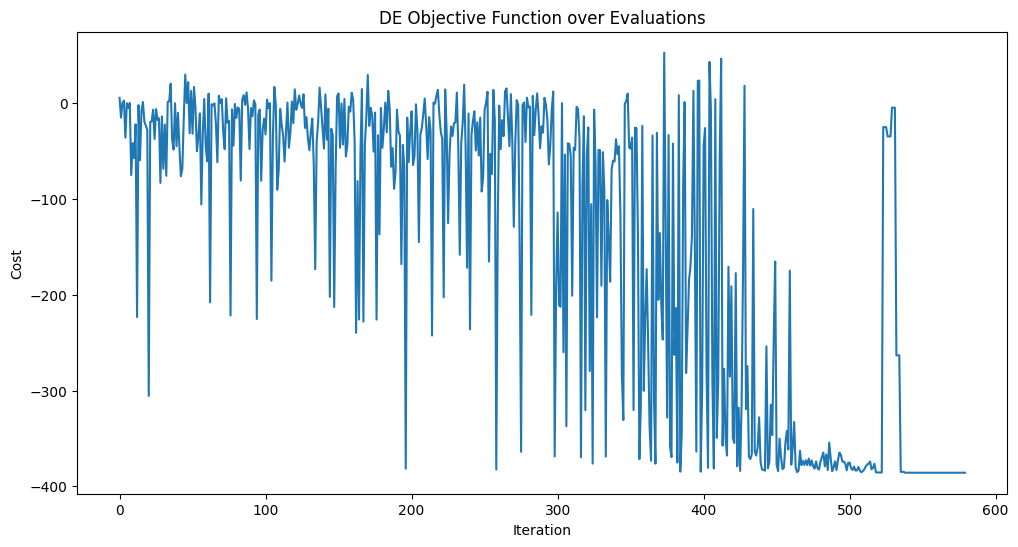

In [ ]:
script_dir = Path().resolve()
filename = script_dir / 'quartet.txt'

quartets = parse_quartet_file(filename)
Q, n, taxa_to_idx = build_qubo_matrix(quartets, A=1.0, B=0.4, gamma=0.0, S0=0)
cost_hamiltonian = qubo_to_cost_hamiltonian(Q, n)

peaked_bitstring = build_and_transpile_circuit_optimization_sample(
    cost_hamiltonian, n, cost_func_estimator,
    reps=1,
    optimization_level=3,
    shots=1000,
    final_shots=10000,
    maxiter=25,
    popsize=10,
    tol=1e-2,
    ibm_backend_name="ibm_marrakesh",
)

if peaked_bitstring is not None:
    idx_to_taxa = {idx: taxon for taxon, idx in taxa_to_idx.items()}
    left_partition  = [idx_to_taxa[i] for i in range(n) if peaked_bitstring[i] == 0]
    right_partition = [idx_to_taxa[i] for i in range(n) if peaked_bitstring[i] == 1]
    print("Left partition: ", left_partition)
    print("Right partition:", right_partition)

    plt.figure(figsize=(12, 6))
    plt.plot(objective_func_vals)
    plt.xlabel("Iteration")
    plt.ylabel("Cost")
    plt.title("DE Objective Function over Evaluations")
    plt.show()
